In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_radial_spectrum, partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, EXTERNAL_DATA_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("experiments", "IterativeFilteringIndividualComponents")

In [3]:
# List of simulation directories

dx = 0.0625
dy = 0.0625

In [4]:
# Plotting Power Spectrum at reconnection time

base_path = f"{DATA_ROOT}/beta_p_1/beta_e_1"

time = 250

File_Bx = f"{base_path}/Bx_ApJ_t{time}.h5"
File_By = f"{base_path}/By_ApJ_t{time}.h5"
File_Bz = f"{base_path}/Bz_ApJ_t{time}.h5"

with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

IMF 1
IMF 2
IMF 3
IMF 4


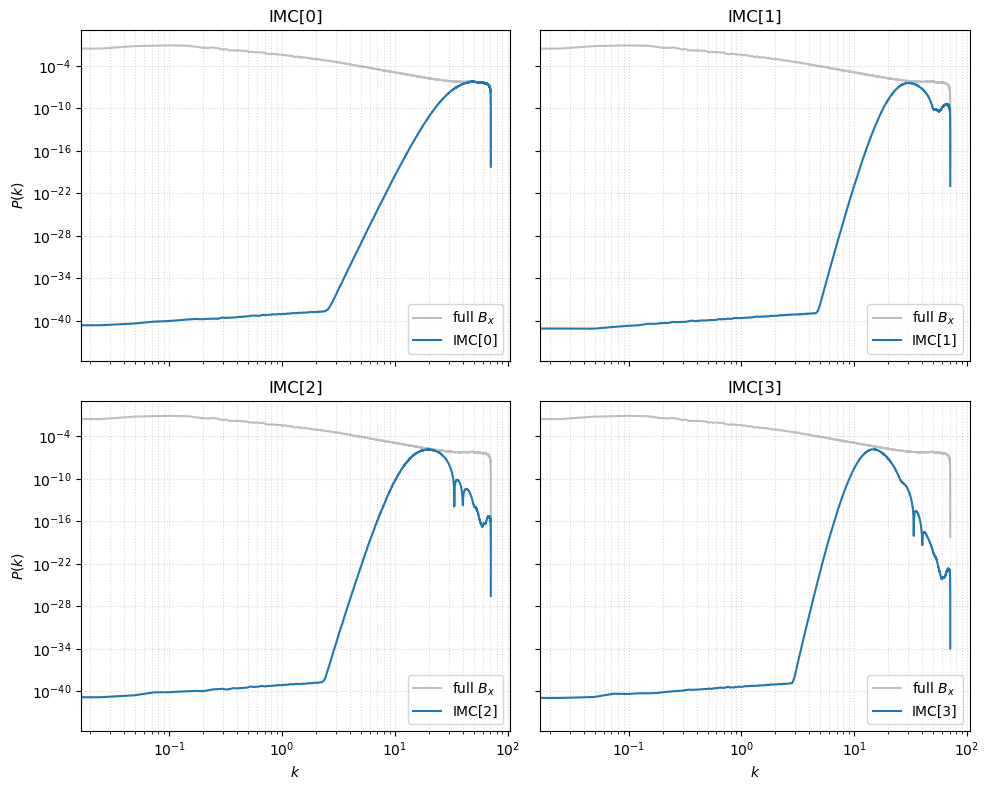

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# Full Bx spectrum (computed once) for reference on every panel
spectrum_full = compute_radial_spectrum(data_Bx, dx, dy)
field = data_Bx
fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=1.6)
fif.run(field)

for i, ax in enumerate(axes.flat):
    spec_imc = compute_radial_spectrum(fif.IMC[i], dx, dy)
    ax.loglog(spectrum_full.kk, spectrum_full.sp,
              color='grey', alpha=0.5, label=r'full $B_x$')
    ax.loglog(spec_imc.kk, spec_imc.sp,
              color='tab:blue', label=f'IMC[{i}]')
    ax.set_title(f'IMC[{i}]')
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend()

for ax in axes[-1, :]:
    ax.set_xlabel(r'$k$')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$P(k)$')

plt.tight_layout()
plt.savefig(RESULTS / "IMC_spectra_grid_Bx.png", dpi=300)
plt.show()

IMF 1
IMF 2
IMF 3
IMF 4


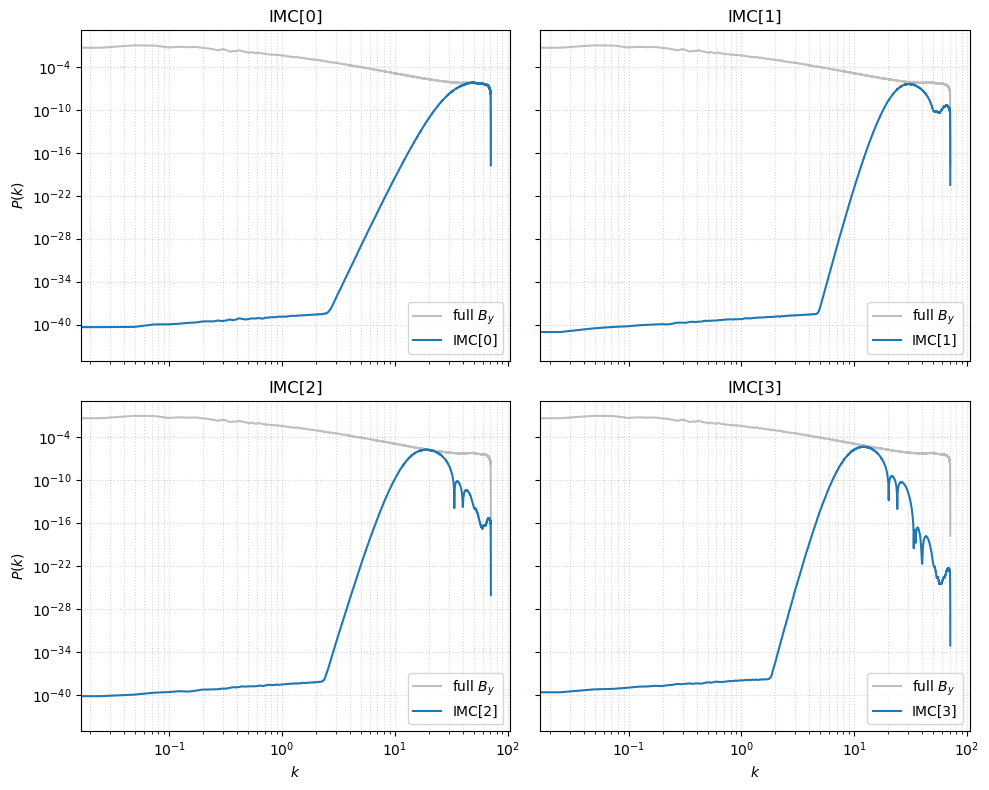

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# Full Bx spectrum (computed once) for reference on every panel
spectrum_full = compute_radial_spectrum(data_By, dx, dy)
field = data_By
fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=1.6)
fif.run(field)

for i, ax in enumerate(axes.flat):
    spec_imc = compute_radial_spectrum(fif.IMC[i], dx, dy)
    ax.loglog(spectrum_full.kk, spectrum_full.sp,
              color='grey', alpha=0.5, label=r'full $B_y$')
    ax.loglog(spec_imc.kk, spec_imc.sp,
              color='tab:blue', label=f'IMC[{i}]')
    # ax.axvline(4.3192, linestyle='--', color='k', alpha=0.4)
    # ax.axvline(28,     linestyle='--', color='k', alpha=0.4)
    ax.set_title(f'IMC[{i}]')
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend()

for ax in axes[-1, :]:
    ax.set_xlabel(r'$k$')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$P(k)$')

plt.tight_layout()
plt.savefig(RESULTS / "IMC_spectra_grid_By.png", dpi=300)
plt.show()

IMF 1
IMF 2
IMF 3
IMF 4


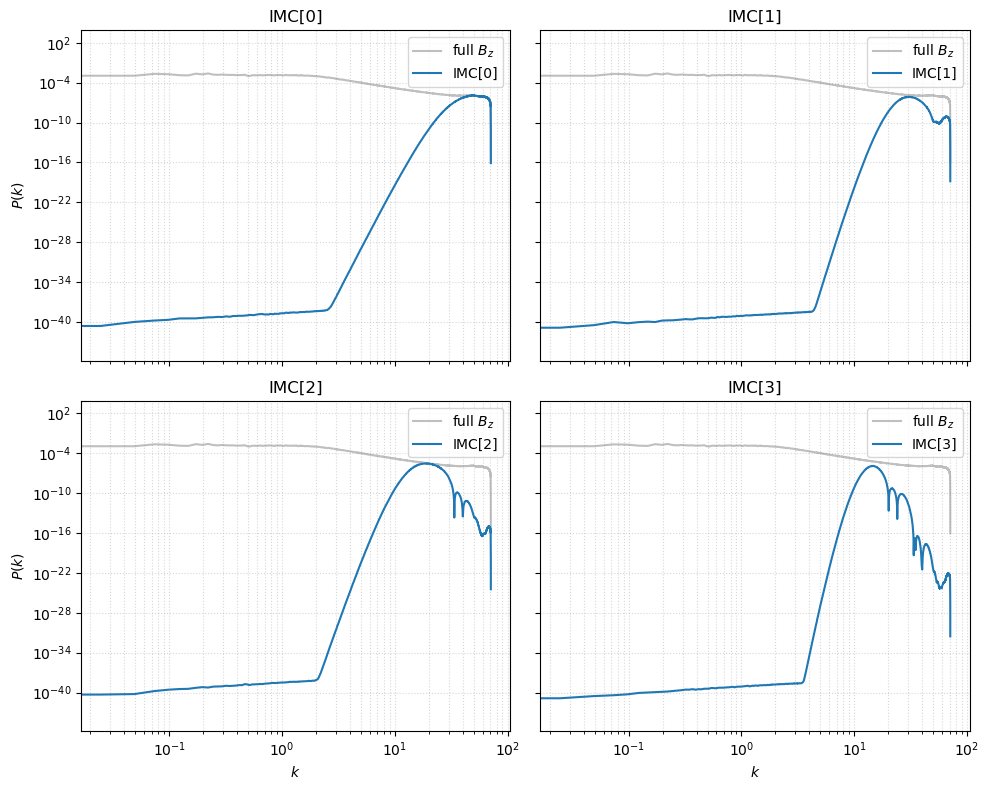

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# Full Bx spectrum (computed once) for reference on every panel
spectrum_full = compute_radial_spectrum(data_Bz, dx, dy)
field = data_Bz
fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=1.6)
fif.run(field)

for i, ax in enumerate(axes.flat):
    spec_imc = compute_radial_spectrum(fif.IMC[i], dx, dy)
    ax.loglog(spectrum_full.kk, spectrum_full.sp,
              color='grey', alpha=0.5, label=r'full $B_z$')
    ax.loglog(spec_imc.kk, spec_imc.sp,
              color='tab:blue', label=f'IMC[{i}]')
    # ax.axvline(4.3192, linestyle='--', color='k', alpha=0.4)
    # ax.axvline(28,     linestyle='--', color='k', alpha=0.4)
    ax.set_title(f'IMC[{i}]')
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend()

for ax in axes[-1, :]:
    ax.set_xlabel(r'$k$')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$P(k)$')

plt.tight_layout()
plt.savefig(RESULTS / "IMC_spectra_grid_Bz.png", dpi=300)
plt.show()

In [41]:
print(f"k        = {spectrum_full.kk[410]:.4f}")
print(f"P_full   = {spectrum_full.sp[410]:.3e}")

for i in range(4):
    spec = compute_radial_spectrum(fif.IMC[i], dx, dy)
    print(f"IMC[{i}]: P[10] = {spec.sp[410]:.3e}")

k        = 10.0629
P_full   = 3.440e-06
IMC[0]: P[10] = 6.029e-24
IMC[1]: P[10] = 4.746e-20
IMC[2]: P[10] = 9.564e-11
IMC[3]: P[10] = 2.920e-11


In [43]:
# Plotting Power Spectrum at reconnection time

# base_path = "/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_0.0625/beta_e_1"
base_path = f"{EXTERNAL_DATA_ROOT}/QMUL/data-franci/data/RunCompa_2Dbig_rms012_modes8"


time = 400
sim_tag = 'EL8modes'

File_Bx = f"{base_path}/Bx_{sim_tag}_t{time}.h5"
File_By = f"{base_path}/By_{sim_tag}_t{time}.h5"
File_Bz = f"{base_path}/Bz_{sim_tag}_t{time}.h5"


with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T


data_Jx =  partial_y_fft(data_Bz, dx)
data_Jy = -partial_x_fft(data_Bz, dx)
data_Jz =  partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dx)

# Compute radial spectra
spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
spectrum_By = compute_radial_spectrum(data_By, dx, dy)
spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)

spectrum_Jx = compute_radial_spectrum(data_Jx, dx, dy)
spectrum_Jy = compute_radial_spectrum(data_Jy, dx, dy)
spectrum_Jz = compute_radial_spectrum(data_Jz, dx, dy)

spectrum_B = np.recarray(spectrum_Bx.shape, dtype=spectrum_Bx.dtype)
spectrum_B.kk = spectrum_Bx.kk
spectrum_B.sp = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp

spectrum_J = np.recarray(spectrum_Jx.shape, dtype=spectrum_Jx.dtype)
spectrum_J.kk = spectrum_Jx.kk
spectrum_J.sp = spectrum_Jx.sp + spectrum_Jy.sp + spectrum_Jz.sp

In [44]:
# data_Bx_filtered = iterative_filtering(data_Bx,3)
# data_By_filtered = iterative_filtering(data_By,3)
# data_Bz_filtered = iterative_filtering(data_Bz,3)

data_Bx_filtered, data_By_filtered, data_Bz_filtered = iterative_filtering3D(data_Bx, data_By, data_Bz, 1, Xi=3.0)

IMF 1
IMF 2
IMF 3
IMF 4
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so


In [45]:
spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, dx, dy)
spectrum_Byf = compute_radial_spectrum(data_By_filtered, dx, dy)
spectrum_Bzf = compute_radial_spectrum(data_Bz_filtered, dx, dy)

spectrum_Bf = np.recarray(spectrum_Bxf.shape, dtype=spectrum_Bxf.dtype)
spectrum_Bf.kk = spectrum_Bxf.kk
spectrum_Bf.sp = spectrum_Bxf.sp + spectrum_Byf.sp + spectrum_Bzf.sp

data_Jx_filtered = partial_y_fft(data_Bz_filtered,dx)
data_Jy_filtered = -partial_x_fft(data_Bz_filtered,dy)
data_Jz_filtered = partial_x_fft(data_By_filtered,dy)-partial_y_fft(data_Bx_filtered,dx)

spectrum_Jxf = compute_radial_spectrum(data_Jx_filtered, dx, dy)
spectrum_Jyf = compute_radial_spectrum(data_Jy_filtered, dx, dy)
spectrum_Jzf = compute_radial_spectrum(data_Jz_filtered, dx, dy)

spectrum_Jf = np.recarray(spectrum_Jxf.shape, dtype=spectrum_Jxf.dtype)
spectrum_Jf.kk = spectrum_Jxf.kk
spectrum_Jf.sp = spectrum_Jxf.sp + spectrum_Jyf.sp + spectrum_Jzf.sp

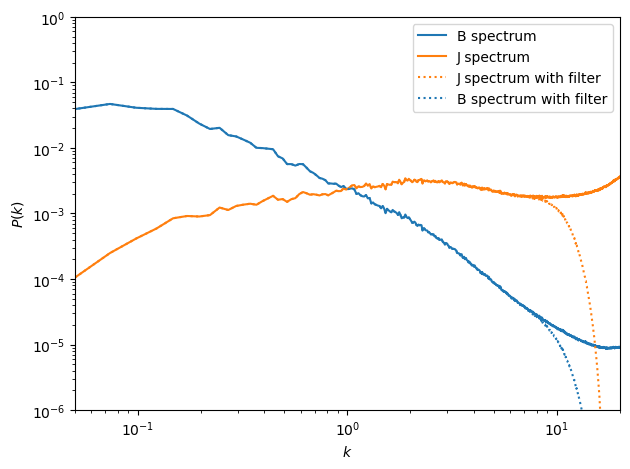

In [46]:
# Plot unfiltered first and capture line objects

line_B, = plt.loglog(
    spectrum_B.kk,
    spectrum_B.sp,
    label="B spectrum"
)

line_J, = plt.loglog(
    spectrum_J.kk,
    spectrum_J.sp,
    label="J spectrum"
)

plt.loglog(
    spectrum_Jf.kk,
    spectrum_Jf.sp,
    linestyle=":",
    color=line_J.get_color(),
    label="J spectrum with filter"
)

plt.loglog(
    spectrum_Bf.kk,
    spectrum_Bf.sp,
    linestyle=":",
    color=line_B.get_color(),
    label="B spectrum with filter"
)

plt.xlabel(r"$k$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 20)
plt.ylim(1e-6, 1)
# plt.axvline(x=38.5105, linestyle='--', color='red', label='kdi at SNR=3')

plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "JB_Spectrum", dpi=300)
plt.show()